# What does YOLO see?
## No training × CPU × your photos

Use a **pretrained YOLO11n model** to draw boxes around objects in photos and explore different settings.

You will:
1. Run a bundled example and interpret boxes, labels, and confidence scores.
2. Upload your own photo and change confidence thresholds and class filters.
3. Export annotated images and CSV files to compare successes and failures.

| Lesson | Task | Training required? |
|---|---|---|
| LeNet | Assign one class to an image | Yes |
| U-Net | Restore a clean image from a noisy one | Yes |
| YOLO11n | Locate and classify multiple objects in one image | **No** |

This is a detector pretrained on 80 COCO classes, not the Imagenette classifier. You do not need to download the COCO dataset. The classes include people, cars, dogs, and cups, but do not cover every possible object.

Model source: [Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11/).

## 1. Install packages (first time only)

Python 3.11 / 3.12 is recommended. Skip the installation cell if you have already followed the README.
In Colab, or if packages are missing, remove the `#` before `%pip` below and run the cell. If prompted, restart the kernel and continue from section 2.

The README includes a CPU-only PyTorch installation option for local use, which avoids downloading unnecessary GPU packages.

In [4]:
# Uncomment only if needed:
%pip install ultralytics==8.4.197 opencv-python==4.11.0.86 "ipywidgets>=8.1,<9"

Defaulting to user installation because normal site-packages is not writeable
  Using cached ultralytics-8.4.197-py3-none-any.whl.metadata (47 kB)
  Using cached opencv_python-4.11.0.86-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached polars-2.1.0-py3-none-any.whl.metadata (11 kB)
  Using cached nvidia_ml_py-13.615.71-py3-none-any.whl.metadata (9.7 kB)
  Using cached ultralytics_platform-0.1.102-py3-none-any.whl.metadata (17 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached polars_runtime_32-2.1.0-cp311-abi3-win_amd64.whl.metadata (1.5 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
Using cached ultralytics-8.4.197-py3-none-any.whl (1.4 MB)
Using cached opencv_python-4.11.0.86-cp37-abi3-win_amd64.whl (39.5 MB)
Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
Using cache

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 2. Load the pretrained model

The first run downloads approximately 5.4 MB of weights as `yolo11n.pt`. Later runs reuse the file in `weights/`.
The `n` stands for the nano model, chosen here to reduce CPU requirements.

**Pretrained** means someone has already trained the model. **Inference** means using fixed model weights to predict what is in a new photo.
We only call `predict()`: there is no `train()` call, backpropagation, or weight update.

The functions below also handle photo orientation, RGB / BGR channel order, and saving results.

In [5]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from io import BytesIO
import argparse
import csv
import html
import json
import os
import time
import uuid

# Keep package settings with this tutorial rather than in the user's global config.
os.environ.setdefault("YOLO_CONFIG_DIR", str(Path(".yolo_config").resolve()))
import torch
import ultralytics
from ultralytics import YOLO, settings
from ultralytics.utils import ASSETS
from PIL import Image, ImageOps

settings.update({"sync": False})
torch.set_num_threads(min(2, os.cpu_count() or 1))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\TooDou\Documents\python\ML\.yolo_config\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [6]:
def load_model():
    Path("weights").mkdir(exist_ok=True)
    # First run downloads the official pretrained checkpoint; later runs reuse it.
    model = YOLO("weights/yolo11n.pt")
    print(f"YOLO11n | CPU | {len(model.names)} classes | Ultralytics {ultralytics.__version__}")
    return model


def read_image(source):
    """Apply camera orientation, return detached RGB pixels, never alter the input file."""
    if isinstance(source, Image.Image):
        return ImageOps.exif_transpose(source).convert("RGB")
    if isinstance(source, (bytes, bytearray, memoryview)):
        if len(source) > 20 * 1024 * 1024:
            raise ValueError("Please use an image smaller than 20 MB.")
        source = BytesIO(bytes(source))
    with Image.open(source) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def detect(model, source, confidence=0.25, image_size=640, class_id=None, iou=0.7):
    """Return an annotated PIL RGB image and JSON-serializable predictions."""
    if not 0 <= confidence <= 1 or not 0 < iou <= 1:
        raise ValueError("Confidence must be in [0,1], IoU in (0,1].")
    if image_size not in (320, 480, 640):
        raise ValueError("Choose image_size 320, 480 or 640.")
    if class_id is not None and class_id not in model.names:
        raise ValueError("Unknown class ID.")
    image = read_image(source)
    started = time.perf_counter()
    result = model.predict(image, device="cpu", imgsz=image_size, conf=confidence,
                           iou=iou, classes=None if class_id is None else [class_id],
                           max_det=100, verbose=False)[0]
    elapsed = (time.perf_counter() - started) * 1000
    rows = []
    if result.boxes is not None:
        for box in result.boxes:
            label = int(box.cls.item())
            coords = box.xyxy[0].tolist()
            rows.append(dict(class_id=label, label=model.names[label],
                             confidence=round(float(box.conf.item()), 4),
                             **{k: round(v, 1) for k, v in zip(["x1", "y1", "x2", "y2"], coords)}))
    # result.plot() returns OpenCV BGR; Pillow and notebooks expect RGB.
    annotated = Image.fromarray(result.plot(pil=False)[..., ::-1])
    report = dict(model="yolo11n.pt", pretrained_dataset="COCO", device="cpu",
                  ultralytics=ultralytics.__version__, torch=str(torch.__version__),
                  original_width=image.width, original_height=image.height,
                  confidence_threshold=confidence, image_size=image_size,
                  class_filter=class_id, nms_iou=iou, max_detections=100,
                  predict_wall_ms=round(elapsed, 2),
                  counts=dict(Counter(row["label"] for row in rows)), detections=rows)
    return annotated, report


def save_result(annotated, report, output="outputs"):
    """Each click gets a new directory, so earlier comparisons are retained."""
    destination = Path(output) / (datetime.now().strftime("%Y%m%d-%H%M%S") + "-" + uuid.uuid4().hex[:6])
    destination.mkdir(parents=True, exist_ok=False)
    annotated.save(destination / "detections.png")
    (destination / "detections.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    fields = ["class_id", "label", "confidence", "x1", "y1", "x2", "y2"]
    with (destination / "detections.csv").open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(report["detections"])
    return destination


def report_table(report):
    headers = ["label", "confidence", "x1", "y1", "x2", "y2"]
    body = "".join("<tr>" + "".join(f"<td>{html.escape(str(row[k]))}</td>" for k in headers) + "</tr>"
                   for row in report["detections"])
    if not body:
        body = '<tr><td colspan="6">No objects detected with these settings. This does not mean the image contains no objects.</td></tr>'
    return "<table><thead><tr>" + "".join(f"<th>{h}</th>" for h in headers) + "</tr></thead><tbody>" + body + "</tbody></table>"

In [7]:
model = load_model()
print("Supported classes:")
print(", ".join(f"{i}: {name}" for i, name in model.names.items()))

YOLO11n | CPU | 80 classes | Ultralytics 8.4.197
Supported classes:
0: person, 1: bicycle, 2: car, 3: motorcycle, 4: airplane, 5: bus, 6: train, 7: truck, 8: boat, 9: traffic light, 10: fire hydrant, 11: stop sign, 12: parking meter, 13: bench, 14: bird, 15: cat, 16: dog, 17: horse, 18: sheep, 19: cow, 20: elephant, 21: bear, 22: zebra, 23: giraffe, 24: backpack, 25: umbrella, 26: handbag, 27: tie, 28: suitcase, 29: frisbee, 30: skis, 31: snowboard, 32: sports ball, 33: kite, 34: baseball bat, 35: baseball glove, 36: skateboard, 37: surfboard, 38: tennis racket, 39: bottle, 40: wine glass, 41: cup, 42: fork, 43: knife, 44: spoon, 45: bowl, 46: banana, 47: apple, 48: sandwich, 49: orange, 50: broccoli, 51: carrot, 52: hot dog, 53: pizza, 54: donut, 55: cake, 56: chair, 57: couch, 58: potted plant, 59: bed, 60: dining table, 61: toilet, 62: tv, 63: laptop, 64: mouse, 65: remote, 66: keyboard, 67: cell phone, 68: microwave, 69: oven, 70: toaster, 71: sink, 72: refrigerator, 73: book, 74: 

## 3. Run one photo first

The bundled example is `assets/bus.jpg` from the Ultralytics package.

- `confidence=0.25`: show predictions with scores at or above 0.25.
- `image_size=640`: the target size used when resizing and padding the input. Output boxes are mapped back to the original image.
- `class_id=None`: keep all classes.

**A score is not an accuracy measurement.** A score of 0.9 does not establish that the prediction has a verified 90% probability of being correct.

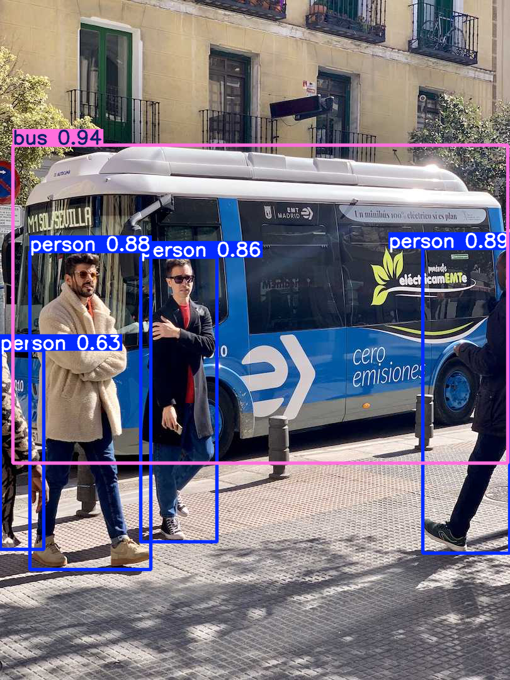

label,confidence,x1,y1,x2,y2
bus,0.9402,20.5,230.4,806.8,735.3
person,0.8885,671.0,394.6,809.8,878.6
person,0.8784,47.4,399.7,239.2,904.1
person,0.8575,223.1,408.7,344.5,860.4
person,0.6251,0.0,556.4,69.1,872.4


Detection counts by class: {'bus': 1, 'person': 4}
Original image size: 810 × 1080
Predict call time: 36.35 ms


In [9]:
from IPython.display import display, HTML
example_image, example_report = detect(model, ASSETS / "bus.jpg")
preview = example_image.copy()
preview.thumbnail((900, 680))
display(preview)
display(HTML(report_table(example_report)))
print("Detection counts by class:", example_report["counts"])
print("Original image size:", example_report["original_width"], "×", example_report["original_height"])
print("Predict call time:", example_report["predict_wall_ms"], "ms")

In the table, `x1,y1` is the top-left corner and `x2,y2` is the bottom-right corner, in original-image pixels.
The box count is the number of retained predictions. Objects may be missed or incorrectly detected. This example keeps at most 100 boxes.

## 4. Interactive playground

Choose an example or upload your own photo. After changing settings, click **Run detection**. Click **Save result** to keep the annotated image and CSV.

Photos are processed in the current notebook environment: locally with local Jupyter, or in the cloud with Colab. The HTML reading copy does not provide a working interactive interface.

The next cell enables widgets in Colab and is skipped automatically in local environments.

In [10]:
try:
    from google.colab import output as colab_output
except ImportError:
    pass
else:
    colab_output.enable_custom_widget_manager()

In [11]:
def uploaded_bytes(value):
    # Support ipywidgets 7 dictionary and ipywidgets 8 tuple/list formats.
    if not value:
        raise ValueError("Please upload a JPG, PNG, or WebP image first.")
    entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
    return bytes(entry["content"])


def build_playground(model):
    import ipywidgets as widgets
    from IPython.display import display, HTML, FileLink

    upload = widgets.FileUpload(accept=".jpg,.jpeg,.png,.webp", multiple=False, description="Upload photo")
    source = widgets.Dropdown(options=[("Example: street and bus", "bus"), ("Example: people", "zidane"),
                                      ("My photo", "upload")], description="Image:")
    conf = widgets.FloatSlider(value=0.25, min=0.05, max=0.95, step=0.05,
                               description="Confidence:", readout_format=".2f", continuous_update=False)
    size = widgets.Dropdown(options=[320, 480, 640], value=640, description="Input size:")
    category = widgets.Dropdown(options=[("All classes", None)] + [(v, k) for k, v in model.names.items()],
                                description="Class:")
    iou = widgets.FloatSlider(value=0.7, min=0.1, max=0.9, step=0.1, description="NMS IoU:",
                              continuous_update=False)
    advanced = widgets.Accordion(children=[widgets.VBox([iou])])
    advanced.set_title(0, "Advanced: overlapping boxes (optional)")
    advanced.selected_index = None
    run_button = widgets.Button(description="Run detection", button_style="primary", icon="search")
    save_button = widgets.Button(description="Save result", icon="save", disabled=True)
    output, saved = widgets.Output(), widgets.Output()
    state = {}

    def changed_upload(change):
        if change["new"]:
            source.value = "upload"

    def run_clicked(_):
        run_button.disabled = True
        save_button.disabled = True
        state.clear()
        saved.clear_output()
        with output:
            output.clear_output(wait=True)
            try:
                selected = uploaded_bytes(upload.value) if source.value == "upload" else ASSETS / f"{source.value}.jpg"
                annotated, report = detect(model, selected, conf.value, size.value, category.value, iou.value)
                state.update(image=annotated, report=report)
                print(f"Detected {len(report['detections'])} boxes; counts by class: {report['counts']}")
                print(f"Predict call: {report['predict_wall_ms']:.0f} ms (the first call may be slower; plotting excluded)")
                print(f"Settings: conf={conf.value:.2f}, imgsz={size.value}, class={category.label}, IoU={iou.value:.1f}")
                preview = annotated.copy()
                preview.thumbnail((960, 720))
                display(preview)
                display(HTML(report_table(report)))
                save_button.disabled = False
            except Exception as exc:
                print(f"Detection failed: {exc}")
                print("Check the image format and model download. Try a bundled example first.")
            finally:
                run_button.disabled = False

    def save_clicked(_):
        if not state:
            return
        with saved:
            saved.clear_output(wait=True)
            destination = save_result(state["image"], state["report"])
            print(f"Saved the displayed result to: {destination}")
            for name in ("detections.png", "detections.csv", "detections.json"):
                display(FileLink(str(destination / name)))
            print("In Colab, if these links do not work, download the files from outputs using the Files panel.")

    upload.observe(changed_upload, names="value")
    run_button.on_click(run_clicked)
    save_button.on_click(save_clicked)
    panel = widgets.VBox([
        widgets.HTML("<h3>What does YOLO see?</h3><p>Choose an example or upload a photo, adjust the settings, then click Run detection. Click again after changing settings.</p>"),
        widgets.HBox([source, upload]), conf, widgets.HBox([size, category]), advanced,
        widgets.HBox([run_button, save_button]), output, saved,
    ])
    # Controls returned for reproducible checks and optional customization.
    return panel, dict(upload=upload, source=source, confidence=conf, size=size,
                       category=category, run=run_button, save=save_button, state=state)

In [12]:
panel, controls = build_playground(model)
display(panel)

### Things to try

| Activity | Action | What to observe |
|---|---|---|
| Desk scavenger hunt | Use a photo of a cup, phone, mouse, or keyboard | What does the model miss? |
| Threshold challenge | Compare 0.15 and 0.75 on the same photo | Were the disappearing boxes correct or incorrect? |
| One class only | Select person or car | Which boxes remain? |
| Small objects in the distance | Compare input sizes 320 and 640 | How do detections and runtime change? |
| Find blind spots | Try occlusion, dim lighting, or objects outside the 80 classes | What does no detection mean? |

Increasing the confidence threshold filters out lower-scoring predictions. **It does not retrain the model or guarantee that every retained prediction is correct.**

The advanced NMS IoU setting controls filtering of overlapping boxes within the same class. A lower value generally removes overlapping boxes more aggressively, but can remove boxes for different objects in crowded scenes. Start with the default of 0.7.

## 5. Compare input sizes in code

Use the same photo and threshold. Warm up each input size, then run it three times and take the median. This is a record of your current environment, not a formal performance benchmark.
Timing includes preprocessing, inference, and postprocessing within `predict`, but excludes reading the image, plotting, and saving. Initialization and system load can also affect runtime.

{'imgsz': 320, 'median_predict_ms': 18.27, 'boxes': 5, 'counts': {'person': 4, 'bus': 1}}


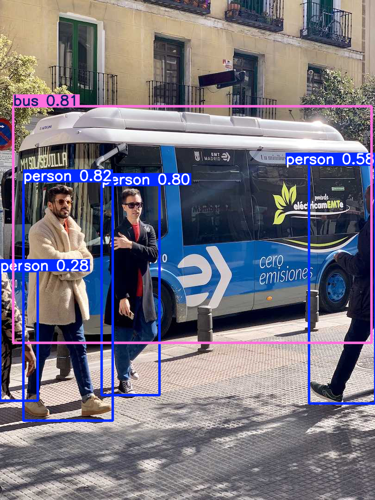

{'imgsz': 640, 'median_predict_ms': 34.48, 'boxes': 5, 'counts': {'bus': 1, 'person': 4}}


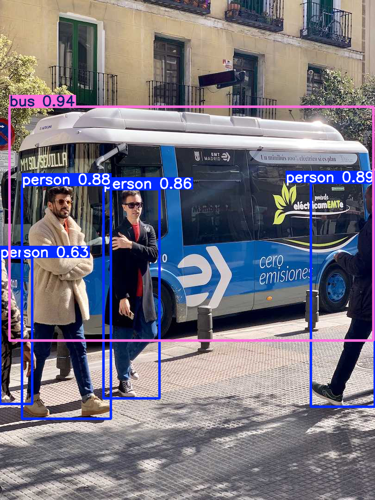

In [13]:
import statistics
comparison = []
for image_size in (320, 640):
    detect(model, ASSETS / "bus.jpg", image_size=image_size)  # warm up this size
    times = []
    for _ in range(3):
        picture, report = detect(model, ASSETS / "bus.jpg", image_size=image_size)
        times.append(report["predict_wall_ms"])
    comparison.append({"imgsz": image_size, "median_predict_ms": round(statistics.median(times), 2),
                       "boxes": len(report["detections"]), "counts": report["counts"]})
    print(comparison[-1])
    picture.thumbnail((720, 500))
    display(picture)


More boxes do not necessarily mean better accuracy. Evaluating accuracy / mAP requires ground-truth annotations and an appropriate evaluation procedure. This activity does not treat box count as accuracy.

## 6. Specify an image path instead of using the upload button

If widgets are unavailable, upload the photo through the Jupyter / Colab file panel, then update the path and uncomment the code below.
PNG, JPG, and WebP work directly. Convert HEIC photos to JPG first.

In [10]:
# picture, report = detect(model, "my_photo.jpg", confidence=0.35, image_size=640)
# display(picture)
# print(report["counts"])
# saved_to = save_result(picture, report)
# print("Saved to:", saved_to)


## 7. Save results

The next cell saves the bus example from section 3. The interactive interface provides the same feature.
Each save creates a new directory with an annotated PNG, a CSV of detections, and a JSON file containing settings and results.

In Colab, download files from `outputs` using the Files panel on the left.

In [11]:
saved_to = save_result(example_image, example_report)
print("Example result saved to:", saved_to)
print("Files: detections.png / detections.csv / detections.json")

Example result saved to: outputs\20261102-022549-1a87aa
Files: detections.png / detections.csv / detections.json


## 8. What can you do now?

You can load an existing model, run detection, change inference settings, inspect outputs, and save results.

Possible follow-up lessons:

- **Instance segmentation:** use `yolo11n-seg.pt` to examine object outlines. You will also need to read and display masks.
- **Pose estimation:** use `yolo11n-pose.pt` to examine human keypoints. You will also need to read keypoints.
- **Custom objects:** annotate your own dataset before fine-tuning. Renaming labels or lowering a threshold cannot teach a new object class.

This example implements object detection only and does not require a webcam or live video equipment.

### Official references

- [YOLO11 and pretrained models](https://docs.ultralytics.com/models/yolo11/)
- [Prediction arguments and outputs](https://docs.ultralytics.com/modes/predict/)
- [COCO classes](https://docs.ultralytics.com/datasets/detect/coco/)
- [Ultralytics source code and licensing information](https://github.com/ultralytics/ultralytics)

Example photos come from the Ultralytics package assets. Weights are downloaded from the official source on first use.